<a href="https://colab.research.google.com/github/Harsh943-hash/FoAI/blob/Exercises/Ex_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

seed=0, H=  0, train MSE=0.6361, validation MSE=0.9377
seed=0, H=  1, train MSE=0.4278, validation MSE=0.6396
seed=0, H=  2, train MSE=0.1989, validation MSE=0.2825
seed=0, H=  3, train MSE=0.0752, validation MSE=0.1914
seed=0, H=  5, train MSE=0.0627, validation MSE=0.2321
seed=0, H= 10, train MSE=0.0080, validation MSE=0.5872
seed=0, H= 20, train MSE=0.0108, validation MSE=0.2908
seed=0, H= 50, train MSE=0.0097, validation MSE=0.2593
seed=0, H=100, train MSE=0.0112, validation MSE=0.2656
seed=1, H=  0, train MSE=0.6361, validation MSE=0.9377
seed=1, H=  1, train MSE=0.4278, validation MSE=0.6396
seed=1, H=  2, train MSE=0.1989, validation MSE=0.2825
seed=1, H=  3, train MSE=0.0752, validation MSE=0.1914
seed=1, H=  5, train MSE=0.0226, validation MSE=0.1682
seed=1, H= 10, train MSE=0.0167, validation MSE=0.3035
seed=1, H= 20, train MSE=0.0012, validation MSE=0.7024
seed=1, H= 50, train MSE=0.0041, validation MSE=0.4240
seed=1, H=100, train MSE=0.0097, validation MSE=0.3327


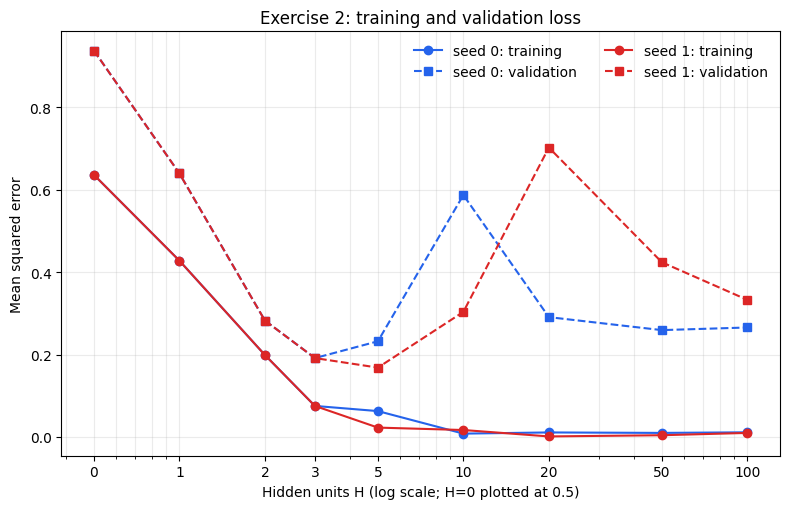


Summary:
seed 0: lowest validation MSE at H=3 (train=0.0752, val=0.1914)
seed 1: lowest validation MSE at H=5 (train=0.0226, val=0.1682)


In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from types import SimpleNamespace

torch.set_default_dtype(torch.float64)

# Recreate the coursework data exactly (120 points, seed 2026, noise SD 0.3).
rng = np.random.default_rng(2026)
x = rng.uniform(-2.0, 2.0, size=120)
y = np.sin(3.0 * x) + 0.3 * x**2 + 0.3 * rng.standard_normal(120)

# Coursework fit.py functions used in this experiment.
def _t(a):
    return torch.as_tensor(np.asarray(a)).reshape(-1, 1)

def make_net(hidden):
    if hidden == 0:
        return nn.Linear(1, 1)
    return nn.Sequential(nn.Linear(1, hidden), nn.Sigmoid(), nn.Linear(hidden, 1))

def mse(net, x, y):
    with torch.no_grad():
        return ((net(_t(x)) - _t(y)) ** 2).mean().item()

def split(x, y, n_train, n_val, seed=0):
    idx = np.random.default_rng(seed).permutation(len(x))
    return ((x[idx[:n_train]], y[idx[:n_train]]),
            (x[idx[n_train:n_train+n_val]], y[idx[n_train:n_train+n_val]]),
            (x[idx[n_train+n_val:]], y[idx[n_train+n_val:]]))

def train(x, y, hidden, epochs=20000, lr=0.01, weight_decay=0.0,
          xval=None, yval=None, seed=0):
    torch.manual_seed(seed)
    net = make_net(hidden)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    X, Y = _t(x), _t(y)
    for _ in range(epochs):
        opt.zero_grad()
        loss = ((net(X) - Y) ** 2).mean()
        loss.backward()
        opt.step()
    return net

fit = SimpleNamespace(split=split, train=train, mse=mse)

# Use the prescribed split once; test data remain untouched.
(xtr, ytr), (xva, yva), (xte, yte) = fit.split(x, y, n_train=30, n_val=30)
Hs = [0, 1, 2, 3, 5, 10, 20, 50, 100]
results = {}
for seed in [0, 1]:
    rows = []
    for H in Hs:
        net = fit.train(xtr, ytr, hidden=H, epochs=20000,
                        xval=xva, yval=yva, seed=seed)
        tr_loss = fit.mse(net, xtr, ytr)
        va_loss = fit.mse(net, xva, yva)
        rows.append((H, tr_loss, va_loss))
        print(f'seed={seed}, H={H:3d}, train MSE={tr_loss:.4f}, validation MSE={va_loss:.4f}')
    results[seed] = rows

fig, ax = plt.subplots(figsize=(8, 5.2))
colors = {0: '#2563eb', 1: '#dc2626'}
for seed in [0, 1]:
    rows = results[seed]
    xx = [0.5 if row[0] == 0 else row[0] for row in rows]
    ax.plot(xx, [row[1] for row in rows], 'o-', color=colors[seed], label=f'seed {seed}: training')
    ax.plot(xx, [row[2] for row in rows], 's--', color=colors[seed], label=f'seed {seed}: validation')
ax.set_xscale('log')
ax.set_xticks([0.5, 1, 2, 3, 5, 10, 20, 50, 100], labels=['0', '1', '2', '3', '5', '10', '20', '50', '100'])
ax.set_xlabel('Hidden units H (log scale; H=0 plotted at 0.5)')
ax.set_ylabel('Mean squared error')
ax.set_title('Exercise 2: training and validation loss')
ax.grid(True, which='both', alpha=0.25)
ax.legend(ncol=2, frameon=False)
plt.tight_layout()
plt.savefig('/content/exercise2.png', dpi=180)
plt.show()

print('\nSummary:')
for seed, rows in results.items():
    best = min(rows, key=lambda row: row[2])
    print(f"seed {seed}: lowest validation MSE at H={best[0]} (train={best[1]:.4f}, val={best[2]:.4f})")


## Exercise 2: choosing capacity with a validation set

**(a) Shape and interpretation.** The training loss generally falls as H increases, from 0.636 at H=0 to values close to zero for larger networks. The validation loss is high for very small H, falls to its lowest region around H=3–5, and then rises or fluctuates at larger H. H=0 and H=1 are too simple to represent the nonlinear pattern, so they underfit. With larger H, the network can fit the 30 training examples very closely, including their noise; the worsening validation loss is evidence of overfitting.

**(b) Choice of H.** The choice is not very clear-cut. With initialization seed 0, H=3 has the lowest validation MSE (0.191); with seed 1, H=5 is lowest (0.168). I would choose a small network in the H=3–5 range, perhaps H=3 for simplicity, while acknowledging that the plot does not identify one uniquely best value.

**(c) Noise floor.** If y=f(x)+ε, where the noise has mean zero and variance σ², then the expected squared prediction error is the squared error from approximating f plus σ². Even a perfect estimate of f therefore cannot make expected validation MSE lower than σ². The lowest validation values here are about 0.17–0.19. They include some remaining function-approximation error and sampling variation, so they suggest a noise variance on the order of 0.1 (roughly; the 30-point validation set cannot estimate it precisely).

**(d) Changing the initialization seed.** The broad pattern is similar: very small networks do poorly, and the best validation results occur at small H. The minimum moves from H=3 to H=5, while some larger-H validation losses change substantially (for example, H=20 rises from 0.291 to 0.702). This shows that 30 validation points give a noisy comparison: they indicate a reasonable capacity range, but cannot pin down the single best H precisely.